# 7.4 · 实时行情与盘中信号

> 回测用的是"已经发生的完整数据"，实盘要在行情**逐拍到达**时实时计算信号、做出决策。
> 本节理解实时行情接入、交易时钟、盘中信号计算与任务调度，并跑通一个完整的盘中模拟。

## 一、实时行情接入

- 实盘通过订阅接收 tick / 分钟 bar，而非一次性读取；
- 行情源要处理延迟、丢包、异常值，并做时间戳管理；
- 教学用 MockMarketFeed 模拟逐拍行情，实盘可替换为券商/交易所订阅，接口一致。
- MarketClock 管理交易时段，只在交易时间内决策。

In [1]:
import sys, numpy as np
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab.market import MarketClock, MockMarketFeed
clk = MarketClock()
print('09:30 可交易?', clk.is_trading_time('09:30'), ' 12:00?', clk.is_trading_time('12:00'))
feed = MockMarketFeed({'A': 10.0}, n_ticks=5, seed=42)
for snap in feed:
    print('tick %d  A=%.3f' % (snap['tick'], snap['prices']['A']))

09:30 可交易? True  12:00? False
tick 1  A=10.003
tick 2  A=9.993
tick 3  A=10.000
tick 4  A=10.010
tick 5  A=9.990


## 二、盘中信号：均线穿越

实时维护一个滚动窗口，用短均线（快速）与长均线（慢速）的关系产生信号：
- 短均线上穿长均线（金叉）→ 买入；
- 短均线下穿长均线（死叉）→ 卖出。

这是最基础的盘中趋势信号，重点在于**每来一个新 tick 就增量更新**，而不是事后看全量数据。

In [2]:
def ma(x, n):
    return np.mean(x[-n:]) if len(x) >= n else np.nan

feed = MockMarketFeed({'A': 10.0}, n_ticks=120, seed=7, vol=0.002)
prices, signals = [], []
for snap in feed:
    p = snap['prices']['A']; prices.append(p)
    fast, slow = ma(prices, 5), ma(prices, 15)
    if np.isnan(fast) or np.isnan(slow):
        sig = 0
    else:
        sig = 1 if fast > slow else -1
    # 信号方向发生变化才记录一次"穿越"
    if signals and sig != signals[-1] and sig != 0:
        signals.append(sig)
    elif not signals:
        signals.append(sig)
    else:
        signals.append(sig)
cross_idx = [i for i in range(1, len(signals)) if signals[i] != signals[i-1]]
print('发生穿越的 tick:', cross_idx)
print('穿越次数:', len(cross_idx))

发生穿越的 tick: [14, 50, 66, 81, 87, 91, 100, 111, 116]
穿越次数: 9


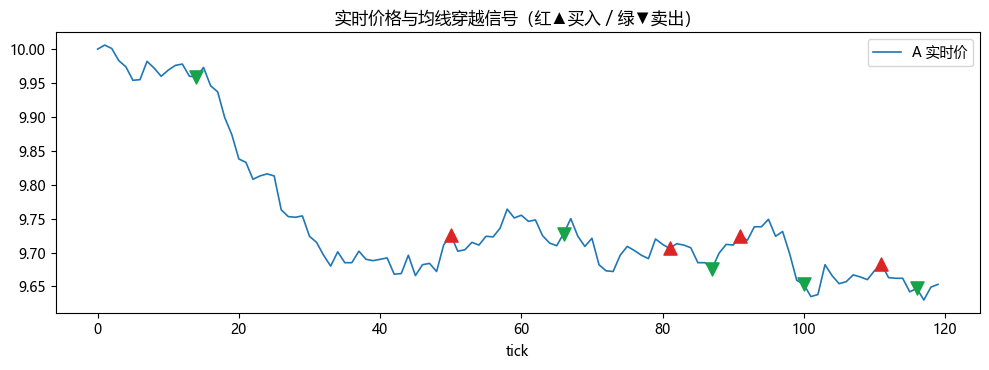

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(prices, label='A 实时价', lw=1.2)
for i in cross_idx:
    ax.scatter(i, prices[i], marker='^' if signals[i] == 1 else 'v',
               color='#dc2626' if signals[i] == 1 else '#16a34a', s=90, zorder=5)
ax.set_title('实时价格与均线穿越信号（红▲买入 / 绿▼卖出）')
ax.set_xlabel('tick'); ax.legend()
plt.tight_layout(); plt.show()

## 三、任务调度：什么时候做什么

实盘一天的动作由调度器按时点触发：

| 时点 | 任务 |
|---|---|
| 盘前 | 加载数据、检查系统、初始化 |
| 09:30 | 开始接收行情、计算信号 |
| 盘中 | 实时信号、风控、下单 |
| 14:57 | 收盘前调整、避免尾盘风险 |
| 15:00 | 收盘清算、对账 |
| 盘后 | 数据更新、复盘、生成报告 |

代码在 live_lab.scheduler。

In [4]:
from live_lab.scheduler import Scheduler
sch = Scheduler()
sch.schedule('pre', lambda c: '盘前检查', 'precheck')
sch.schedule('09:30', lambda c: '开盘运行', 'open')
sch.schedule('15:00', lambda c: '收盘清算', 'close')
for k in ['pre', '09:30', '15:00']:
    print(k, '->', sch.on_time(k))

pre -> [('precheck', '盘前检查')]
09:30 -> [('open', '开盘运行')]
15:00 -> [('close', '收盘清算')]


## 四、增量更新与实时性要点

- 每来新数据只更新滚动窗口和最新信号，不重复全量计算（性能）；
- 信号→下单有延迟，实盘要考虑从计算到成交的时间差；
- 行情可能延迟或缺失，需要超时与数据校验机制；
- 实时信号要和回测逻辑严格一致，否则回测结果无法指导实盘。

## 五、小结与面试要点

- 实时行情逐拍到达，用交易时钟限定决策时间；模拟源可无缝替换为真实订阅。
- 盘中信号增量计算（如均线穿越），调度器按时点串联一天的工作。
- 关注延迟、数据缺失、回测/实盘逻辑一致性。

**面试高频：**
- 实盘信号和回测信号有什么不同？（答：实时逐拍、增量计算、有延迟，回测用完整历史）
- 怎么保证回测和实盘一致？（答：同一套信号逻辑、统一数据口径、模拟盘验证）
- 一天的量化程序如何调度？（答：盘前/开盘/盘中/收盘/盘后分时段任务）

## 动手练习
1. 把均线信号换成实时动量（最近 N tick 涨跌）并标注信号；
2. 给信号加上一个最小阈值，过滤频繁穿越；
3. 列出你策略在实时运行时需要订阅哪些数据。

---
下一节 **7.5 实时风控与监控：事前/事中/事后、报警与容灾**。